# 05 · Application-Time Risk Drivers

**Objective:** find variables available **at the time of application** that separate good from bad borrowers: the first step toward a scorecard / PD model.

**Bottom line:** **every application-time variable carries signal, but none comes close to grade.** Single variables separate risk by only **1.5–1.9×** (income, DTI, purpose, employment length, home ownership), against **7.8×** for grade. Grade is itself the output of Lending Club's model, so it is the **benchmark** a new multivariate model must beat, not an input. Income's **Information Value is 0.06 (weak)** with a monotonic WOE.

| Variable | Lowest-risk bin | Highest-risk bin | Spread |
|---|---|---|---:|
| Annual income | ≥ \$100k: 10.3% | < \$40k: 19.6% | 1.9× |
| Purpose | credit card: 12.0% | small business: 22.8% | 1.9× |
| DTI | 0–10: 11.2% | 30–40: 20.6% | 1.8× |
| Employment length | 10+ years: 12.9% | missing: 21.1% | 1.6× |
| Home ownership | mortgage: 11.8% | rent: 17.2% | 1.5× |

**Rule for feature selection:** only use information **available at the decision point**. Post-origination fields such as `total_pymnt`, `recoveries`, `last_pymnt_d`, `last_fico_range_high` and `debt_settlement_flag` encode the outcome and would cause **data leakage**.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Home ownership

In [2]:
con.sql("""
SELECT home_ownership,
       COUNT(*)                                         AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4)  AS pct_loans,
       CAST(SUM(bad_flag) AS INTEGER)                   AS n_bad,
       ROUND(AVG(bad_flag), 4)                          AS bad_rate
FROM cohort
GROUP BY home_ownership
ORDER BY bad_rate DESC
""").df()

,home_ownership,n_loans,pct_loans,n_bad,bad_rate
0,RENT,191283,0.4291,32857,0.1718
1,OWN,48309,0.1084,7420,0.1536
2,MORTGAGE,206149,0.4625,24231,0.1176
3,ANY,2,0.0000,0,0.0000


* **Renters are riskiest (17.2%)**: fewer assets to absorb a shock.
* **Counter-intuitive:** mortgage holders (11.8%) default less than outright owners (15.4%). A plausible explanation is that a mortgage implies having passed a bank's underwriting, while outright owners include inherited / older, lower-income borrowers. *Hypothesis; to be tested against income.*
* `ANY` has **2 loans**, too few to read; in a scorecard it would be merged into another bin. Sample size is judged on **absolute counts** (and number of bads), not share: OWN at 10.8% still has 48k loans.

## 2. Income bands (binning)
Income is continuous, so it is binned before computing rates. Rules applied:
* every loan falls in **exactly one** bin (lower bound inclusive; a `> 100000` boundary originally dropped **8,430 loans reporting exactly \$100,000**, a common round number);
* missing values get their **own bin** instead of falling into `ELSE`;
* numeric prefixes keep text labels in the right sort order.

In [3]:
income = con.sql("""
SELECT CASE
           WHEN annual_inc IS NULL  THEN '0. Missing'
           WHEN annual_inc < 40000  THEN '1. <40k'
           WHEN annual_inc < 60000  THEN '2. 40-60k'
           WHEN annual_inc < 80000  THEN '3. 60-80k'
           WHEN annual_inc < 100000 THEN '4. 80-100k'
           ELSE                          '5. 100k+'
       END                                              AS income_band,
       COUNT(*)                                         AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4)  AS pct_loans,
       ROUND(AVG(bad_flag), 4)                          AS bad_rate
FROM cohort
GROUP BY income_band
ORDER BY income_band
""").df()

assert income["n_loans"].sum() == con.sql("SELECT COUNT(*) FROM cohort").fetchall()[0][0], "bins must cover every loan"
income

,income_band,n_loans,pct_loans,bad_rate
0,1. <40k,83107,0.1864,0.1961
1,2. 40-60k,120993,0.2714,0.1561
2,3. 60-80k,96892,0.2174,0.1382
3,4. 80-100k,58956,0.1323,0.1201
4,5. 100k+,85795,0.1925,0.1033


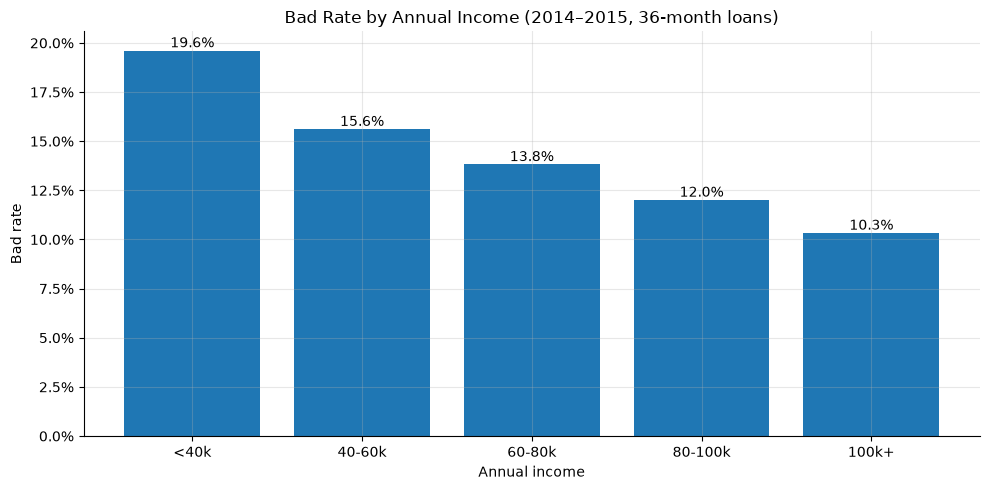

In [4]:
fig, ax = plt.subplots()
ax.bar(income["income_band"].str[3:], income["bad_rate"])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Bad Rate by Annual Income (2014–2015, 36-month loans)")
ax.set_xlabel("Annual income")
ax.set_ylabel("Bad rate")
for x, y in zip(income["income_band"].str[3:], income["bad_rate"]):
    ax.annotate(f"{y:.1%}", (x, y), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "bad_rate_by_income.png", dpi=150)
plt.show()

* The trend is **monotonic**, a requirement for scorecard bins (risk must move in one direction to be explainable to business and regulators).
* The biggest absolute step is < \$40k → \$40–60k (−4.0 pp); afterwards each band drops ~1.8 pp, which is still a **13–15% relative** reduction per band.

## 3. Debt-to-income (DTI)
Profile the distribution before binning: look for missing values and impossible values.

In [5]:
df = con.sql("SELECT dti, bad_flag FROM cohort").df()

print("missing:", df["dti"].isna().sum(), "| > 40:", (df["dti"] > 40).sum())
df["dti"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2)

missing: 2 | > 40: 34


count    445741.00
mean         18.14
std           8.60
min           0.00
1%            2.18
25%          11.76
50%          17.57
75%          24.08
99%          37.80
max         999.00
Name: dti, dtype: float64

* 2 missing values; **max = 999** while the 99th percentile is 37.8. A DTI of 999 means debt payments ≈ 10× income, so it is almost certainly a **placeholder / data error**, not a real borrower.
* The mean (18.1) is pulled above the median (17.6) by these outliers. Binning is robust to them: they simply fall into the top bin.

In [6]:
df["dti_band"] = pd.cut(df["dti"], bins=[0, 10, 20, 30, 40, float("inf")], right=False)

dti = df.groupby("dti_band", observed=True, dropna=False).agg(
    n_loans=("bad_flag", "size"),
    bad_rate=("bad_flag", "mean"),     # mean() skips NULL (indeterminate) loans
)
assert dti["n_loans"].sum() == len(df), "bins must cover every loan"
dti.round(4)

,n_loans,bad_rate
dti_band,,
"[0.0, 10.0)",81307,0.1116
"[10.0, 20.0)",187092,0.1291
"[20.0, 30.0)",135375,0.1672
"[30.0, 40.0)",41933,0.2064
"[40.0, inf)",34,0.2353
NaN,2,0.5


* Bad rate rises **monotonically** from 11.2% (DTI < 10) to 20.6% (30–40).
* The `40+` bin (34 loans) and missing (2 loans) are far too small to read. In a scorecard they would be merged into `30+` and the largest bin respectively (a common rule of thumb is ≥ 5% of the population per bin).

## 4. Employment length
A text variable: `'10+ years'` sorts between `'1 year'` and `'2 years'`, so it is mapped to a number for ordering.

In [7]:
df = con.sql("SELECT emp_length, bad_flag FROM cohort").df()

emp_map = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5,
           "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10}
df["emp_years"] = df["emp_length"].map(emp_map)       # missing stays NaN

emp = (df.groupby("emp_years", dropna=False)
         .agg(n_loans=("bad_flag", "size"), bad_rate=("bad_flag", "mean"))
         .sort_index(na_position="first"))
emp.round(4)

,n_loans,bad_rate
emp_years,,
NaN,28616,0.2111
0.0,37147,0.151
1.0,29811,0.1517
2.0,40558,0.1441
3.0,36216,0.1447
4.0,26426,0.1453
5.0,26047,0.1454
6.0,19387,0.1414
7.0,21109,0.1406


* **Missing is the strongest signal (21.1%)** vs. 14–15% for most tenures. Missing employment can mean unemployed, self-employed or retired. This is **missing not at random**: imputing it would erase the signal, so it gets its own bin.
* Otherwise only `10+ years` stands out (12.9%). A sensible binning: **missing / 0–9 years / 10+ years**.

## 5. Loan purpose
Many unordered categories, some very small.

In [8]:
df = con.sql("SELECT purpose, bad_flag FROM cohort").df()

purpose = df.groupby("purpose").agg(n_loans=("bad_flag", "size"), bad_rate=("bad_flag", "mean"))
purpose["pct_loans"] = purpose["n_loans"] / purpose["n_loans"].sum()
purpose = purpose.sort_values("n_loans", ascending=False)
purpose.round(4)

,n_loans,bad_rate,pct_loans
purpose,,,
debt_consolidation,255890,0.1523,0.5741
credit_card,110780,0.12,0.2485
home_improvement,25822,0.1298,0.0579
other,23488,0.1632,0.0527
major_purchase,8237,0.1416,0.0185
medical,5032,0.1753,0.0113
car,4285,0.1268,0.0096
small_business,4062,0.2283,0.0091
moving,3195,0.2069,0.0072


* **Debt consolidation is 57%** of the book. **Credit-card refinancing is the safest (12.0%)**, possibly rational refinancing of high-rate card debt; **small business is the riskiest (22.8%)**.
* `wedding` (11 loans) and `educational` (1 loan) show 0% bad rate only by chance. Tiny categories must be **merged**, not kept separate, or a model would learn "wedding = no risk". For a scorecard, group by risk level: low (credit card, car, home improvement), mid (debt consolidation, major purchase, vacation, other + tiny categories), high (medical, small business, moving, house, renewable energy).

## 6. Separation power: comparison

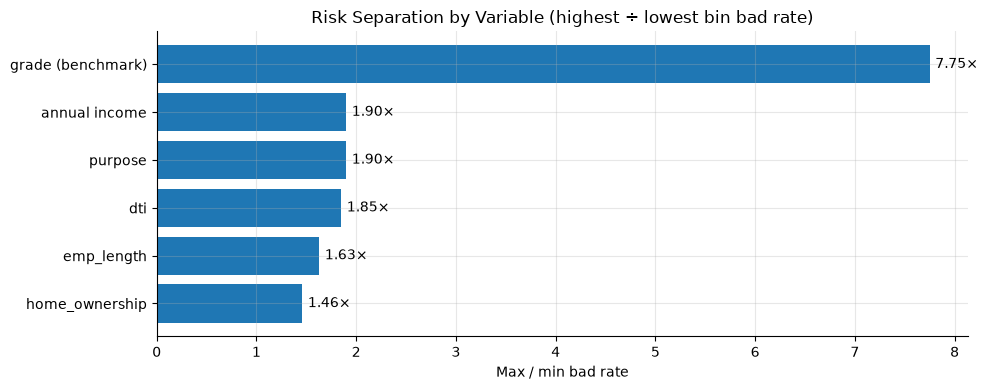

,variable,max / min bad rate
0,grade (benchmark),7.75
1,annual income,1.90
2,purpose,1.90
3,dti,1.85
4,emp_length,1.63
5,home_ownership,1.46


In [9]:
def spread(sql_expr):
    r = con.sql(f"""
        SELECT MAX(bad_rate) / MIN(bad_rate) AS max_min_ratio
        FROM (SELECT {sql_expr} AS bucket, AVG(bad_flag) AS bad_rate, COUNT(*) AS n
              FROM cohort GROUP BY bucket HAVING COUNT(*) >= 300)
    """).fetchall()[0][0]
    return round(r, 2)

ranking = pd.DataFrame({
    "variable": ["grade (benchmark)", "annual income", "purpose", "dti", "emp_length", "home_ownership"],
    "max / min bad rate": [
        spread("grade"),
        spread("CASE WHEN annual_inc < 40000 THEN 1 WHEN annual_inc < 60000 THEN 2 "
               "WHEN annual_inc < 80000 THEN 3 WHEN annual_inc < 100000 THEN 4 ELSE 5 END"),
        spread("purpose"),
        spread("CASE WHEN dti < 10 THEN 1 WHEN dti < 20 THEN 2 WHEN dti < 30 THEN 3 "
               "WHEN dti < 40 THEN 4 WHEN dti >= 40 THEN 5 END"),
        spread("emp_length"),
        spread("home_ownership"),
    ],
}).sort_values("max / min bad rate", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(ranking["variable"][::-1], ranking["max / min bad rate"][::-1])
ax.set_title("Risk Separation by Variable (highest ÷ lowest bin bad rate)")
ax.set_xlabel("Max / min bad rate")
for y, x in enumerate(ranking["max / min bad rate"][::-1]):
    ax.annotate(f"{x:.2f}×", (x, y), xytext=(4, 0), textcoords="offset points", va="center")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "separation_by_variable.png", dpi=150)
plt.show()
ranking

*Buckets with fewer than 300 loans (e.g. `ANY` 2 loans, DTI 40+ 34 loans, `wedding` 11 loans) are excluded from the ratio.*

**Reading:** grade separates risk ~4× better than any single application variable, because it already combines many of them. The max/min ratio is a crude measure: it looks only at the two extreme bins and ignores bin sizes (purpose ranks high because of `small_business`, just 0.9% of loans). **Information Value** fixes this by weighting every bin.

## 7. Weight of Evidence & Information Value
The standard way to score a variable's separation power, using **every** bin and its size:

| Step | Formula |
|---|---|
| Distribution of goods | `dist_good = goods in bin / all goods` |
| Distribution of bads | `dist_bad = bads in bin / all bads` |
| WOE | `ln(dist_good / dist_bad)`: < 0 riskier than average, > 0 safer |
| IV | `Σ (dist_good − dist_bad) × WOE` |

Rule of thumb: < 0.02 useless · 0.02–0.1 weak · 0.1–0.3 medium · 0.3–0.5 strong · > 0.5 suspicious (check for leakage).

In [10]:
import numpy as np

iv = con.sql("""
SELECT CASE WHEN annual_inc IS NULL  THEN '0. Missing'
            WHEN annual_inc < 40000  THEN '1. <40k'
            WHEN annual_inc < 60000  THEN '2. 40-60k'
            WHEN annual_inc < 80000  THEN '3. 60-80k'
            WHEN annual_inc < 100000 THEN '4. 80-100k'
            ELSE                          '5. 100k+'
       END                            AS income_band,
       COUNT(*) FILTER (bad_flag = 0) AS n_good,
       COUNT(*) FILTER (bad_flag = 1) AS n_bad
FROM cohort
GROUP BY income_band
ORDER BY income_band
""").df()

iv["dist_good"] = iv["n_good"] / iv["n_good"].sum()
iv["dist_bad"]  = iv["n_bad"] / iv["n_bad"].sum()
iv["woe"]       = np.log(iv["dist_good"] / iv["dist_bad"])
iv["iv_bin"]    = (iv["dist_good"] - iv["dist_bad"]) * iv["woe"]

assert np.isclose(iv["dist_good"].sum(), 1) and np.isclose(iv["dist_bad"].sum(), 1)
print(f"Income IV: {iv['iv_bin'].sum():.4f}")
iv.round(4)

Income IV: 0.0615


,income_band,n_good,n_bad,dist_good,dist_bad,woe,iv_bin
0,1. <40k,66795,16293,0.1752,0.2526,-0.3655,0.0283
1,2. 40-60k,102085,18887,0.2678,0.2928,-0.0891,0.0022
2,3. 60-80k,83484,13387,0.2190,0.2075,0.0540,0.0006
3,4. 80-100k,51866,7077,0.1361,0.1097,0.2154,0.0057
4,5. 100k+,76919,8864,0.2018,0.1374,0.3844,0.0248


* **Income IV = 0.06: weak**, consistent with its 1.9× spread. Useful only in combination with other variables.
* **WOE rises monotonically** from −0.37 (< \$40k, bads over-represented) to +0.38 (≥ \$100k, goods over-represented), exactly the shape a scorecard needs.
* A bin with zero bads would make WOE infinite, another reason tiny bins must be merged.

## 8. Limitations & next steps
* These are **single-variable** views. Income, DTI and home ownership are likely correlated, so their effects will not simply add up. IV also depends on how the bins are cut.
* **Next:** compute **WOE / Information Value** for all application-time variables (plus FICO at origination, revolving utilization, inquiries, …), then fit a multivariate **PD model** (logistic scorecard and gradient boosting) with **grade as the benchmark** to beat.